# Model Comparison – Why Random Forest?

`analyze.ipynb` builds the final two-stage pipeline with Random Forest. This notebook checks that choice
by comparing it against other common models **on exactly the same data**:

- same cleaning (whitespace stripped from column names and values)
- same 80/20 split (`random_state=10`, stratified for Stage 1)
- same preprocessing (median imputation + scaling for numbers, one-hot encoding for categories)

Every model is tuned with `GridSearchCV` (5-fold cross-validation) on the training set only, then scored once on the test set.

> This notebook **does not save any models** – the app keeps using the pipelines from `analyze.ipynb`.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, r2_score, mean_absolute_error,
                             mean_squared_error)

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor

warnings.filterwarnings("ignore")
%matplotlib inline

## Load and clean data (same steps as `analyze.ipynb`)

In [2]:
df = pd.read_csv(Path("../data/loan_approval_dataset.csv"))
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()
df = df.drop(columns=["loan_id"])
df.shape

(4269, 12)

In [3]:
def make_preprocessor(X):
    cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    numerical = Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())])
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('num', numerical, num_cols),
                              ('cat', categorical, cat_cols)], remainder='drop')

# Stage 1 – Loan approval (classification)

| Model | Why it's here |
|---|---|
| Logistic Regression | Simple linear **baseline** – how much do tree models actually add? |
| Decision Tree | A single tree – how much does a forest of trees add? |
| Random Forest | **Current model** (final settings from `analyze.ipynb`) |
| XGBoost | Gradient-boosted trees – usually the strongest on tabular data |
| LightGBM | Fast gradient-boosted trees |

In [4]:
X = df.drop(columns=['loan_status'])
y = (df['loan_status'] == 'Approved').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3415, 11)  Test: (854, 11)


In [5]:
clf_candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {'model__C': [0.01, 0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=10),
        {'model__max_depth': [None, 4, 8, 12], 'model__min_samples_leaf': [1, 5, 10]}),
    "Random Forest (current)": (
        RandomForestClassifier(n_estimators=400, max_depth=None, max_features=None, random_state=10),
        {}),  # already tuned in analyze.ipynb - kept exactly as deployed
    "XGBoost": (
        XGBClassifier(random_state=10, eval_metric='logloss', n_jobs=1),
        {'model__n_estimators': [200, 400], 'model__max_depth': [3, 5, 7],
         'model__learning_rate': [0.05, 0.1]}),
    "LightGBM": (
        LGBMClassifier(random_state=10, verbose=-1, n_jobs=1),
        {'model__n_estimators': [200, 400], 'model__num_leaves': [15, 31],
         'model__learning_rate': [0.05, 0.1]}),
}

In [6]:
clf_results, clf_fitted = [], {}

for name, (model, grid) in clf_candidates.items():
    pipe = Pipeline([('preprocessor', make_preprocessor(X_train)), ('model', model)])
    search = GridSearchCV(pipe, grid, cv=5, scoring='f1', n_jobs=-1)
    search.fit(X_train, y_train)
    cv_std = search.cv_results_['std_test_score'][search.best_index_]

    best = search.best_estimator_
    start = time.perf_counter()
    best.fit(X_train, y_train)          # time a single refit of the chosen settings
    fit_seconds = time.perf_counter() - start

    pred = best.predict(X_test)
    proba = best.predict_proba(X_test)[:, 1]
    clf_fitted[name] = best
    clf_results.append({
        'Model': name,
        'CV F1 (mean ± std)': f"{search.best_score_:.4f} ± {cv_std:.4f}",
        'Test accuracy': accuracy_score(y_test, pred),
        'Test precision': precision_score(y_test, pred),
        'Test recall': recall_score(y_test, pred),
        'Test F1': f1_score(y_test, pred),
        'Test ROC-AUC': roc_auc_score(y_test, proba),
        'Errors (of 854)': int((pred != y_test).sum()),
        'Fit time (s)': fit_seconds,
        'Best params': {k.replace('model__', ''): v for k, v in search.best_params_.items()} or ('as deployed' if 'current' in name else 'defaults'),
    })
    print(f"done: {name}")

clf_table = pd.DataFrame(clf_results).sort_values('Test F1', ascending=False).reset_index(drop=True)
clf_table.round(4)

done: Logistic Regression


done: Decision Tree


done: Random Forest (current)


done: XGBoost


done: LightGBM


,Model,CV F1 (mean ± std),Test accuracy,Test precision,Test recall,Test F1,Test ROC-AUC,Errors (of 854),Fit time (s),Best params
0,Random Forest (current),0.9845 ± 0.0023,0.9859,0.9905,0.9868,0.9887,0.9986,12,2.5406,as deployed
1,Decision Tree,0.9831 ± 0.0047,0.9848,0.9887,0.9868,0.9877,0.9912,13,0.0216,"{'max_depth': None, 'min_samples_leaf': 10}"
2,XGBoost,0.9857 ± 0.0030,0.9836,0.9832,0.9906,0.9869,0.9986,14,1.3432,"{'learning_rate': 0.1, 'max_depth': 7, 'n_esti..."
3,LightGBM,0.9876 ± 0.0035,0.9824,0.9831,0.9887,0.9859,0.9978,15,0.7421,"{'learning_rate': 0.1, 'n_estimators': 200, 'n..."
4,Logistic Regression,0.9341 ± 0.0054,0.9157,0.9242,0.9416,0.9328,0.9640,72,0.0364,{'C': 0.1}


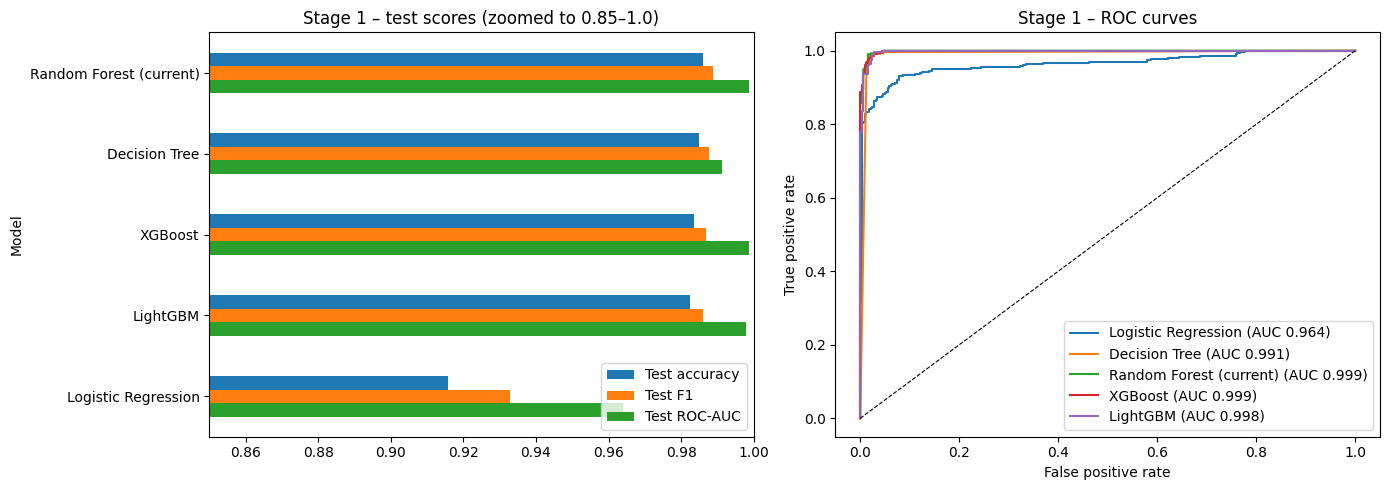

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_df = clf_table.set_index('Model')[['Test accuracy', 'Test F1', 'Test ROC-AUC']]
plot_df.plot(kind='barh', ax=axes[0])
axes[0].set_xlim(0.85, 1.0)
axes[0].set_title("Stage 1 – test scores (zoomed to 0.85–1.0)")
axes[0].invert_yaxis()

for name, model in clf_fitted.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=0.8)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("Stage 1 – ROC curves")
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# Stage 2 – Loan amount (regression)

Trained only on **approved** applicants, with `loan_status` removed (it is always "Approved" here).

| Model | Why it's here |
|---|---|
| Linear Regression | Simple linear **baseline** |
| Random Forest | **Current model** (final settings from `analyze.ipynb`) |
| XGBoost | Gradient-boosted trees |
| LightGBM | Fast gradient-boosted trees |

In [8]:
approved = df[df['loan_status'] == 'Approved']
X_reg = approved.drop(columns=['loan_amount', 'loan_status'])
y_reg = approved['loan_amount']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=10)
print("Train:", Xr_train.shape, " Test:", Xr_test.shape)

Train: (2124, 10)  Test: (532, 10)


In [9]:
reg_candidates = {
    "Linear Regression": (LinearRegression(), {}),
    "Random Forest (current)": (
        RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_split=5,
                              max_features=None, random_state=10),
        {}),  # already tuned in analyze.ipynb - kept exactly as deployed
    "XGBoost": (
        XGBRegressor(random_state=10, n_jobs=1),
        {'model__n_estimators': [200, 400], 'model__max_depth': [3, 5, 7],
         'model__learning_rate': [0.05, 0.1]}),
    "LightGBM": (
        LGBMRegressor(random_state=10, verbose=-1, n_jobs=1),
        {'model__n_estimators': [200, 400], 'model__num_leaves': [15, 31],
         'model__learning_rate': [0.05, 0.1]}),
}

In [ ]:
reg_results, reg_fitted = [], {}

for name, (model, grid) in reg_candidates.items():
    pipe = Pipeline([('preprocessor', make_preprocessor(Xr_train)), ('model', model)])
    search = GridSearchCV(pipe, grid, cv=5, scoring='r2', n_jobs=-1)
    search.fit(Xr_train, yr_train)
    cv_std = search.cv_results_['std_test_score'][search.best_index_]

    best = search.best_estimator_
    start = time.perf_counter()
    best.fit(Xr_train, yr_train)
    fit_seconds = time.perf_counter() - start

    pred = best.predict(Xr_test)
    reg_fitted[name] = best
    reg_results.append({
        'Model': name,
        'CV R² (mean ± std)': f"{search.best_score_:.4f} ± {cv_std:.4f}",
        'Test R²': r2_score(yr_test, pred),
        'Test MAE (₹ lakh)': mean_absolute_error(yr_test, pred) / 1e5,
        'Test RMSE (₹ lakh)': np.sqrt(mean_squared_error(yr_test, pred)) / 1e5,
        'Fit time (s)': fit_seconds,
        'Best params': {k.replace('model__', ''): v for k, v in search.best_params_.items()} or ('as deployed' if 'current' in name else 'defaults'),
    })
    print(f"done: {name}")

reg_table = pd.DataFrame(reg_results).sort_values('Test R²', ascending=False).reset_index(drop=True)
reg_table.round(4)

done: Linear Regression


done: Random Forest (current)


done: XGBoost


done: LightGBM


,Model,CV R² (mean ± std),Test R²,Test MAE (₹ lakh),Test RMSE (₹ lakh),Fit time (s),Best params
0,Linear Regression,0.8702 ± 0.0102,0.8687,25.2442,32.9278,0.0262,defaults
1,XGBoost,0.8732 ± 0.0078,0.8679,24.9517,33.0245,1.0728,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."
2,Random Forest (current),0.8690 ± 0.0098,0.8645,25.1169,33.4429,3.8474,as deployed
3,LightGBM,0.8686 ± 0.0066,0.8575,25.3558,34.2993,0.3525,"{'learning_rate': 0.05, 'n_estimators': 200, '..."


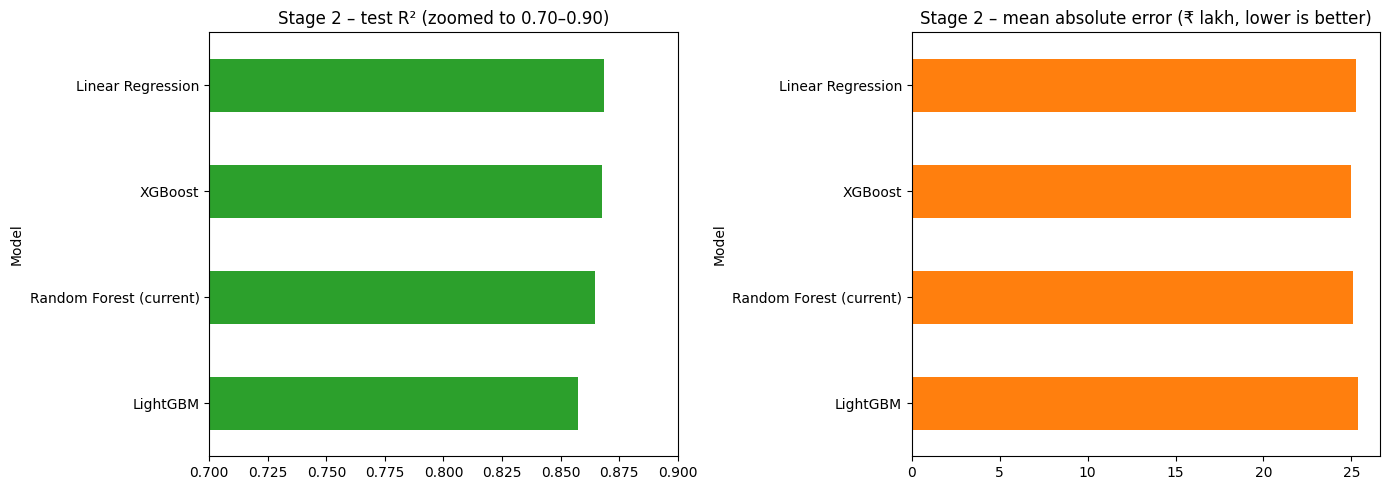

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

reg_table.set_index('Model')['Test R²'].plot(kind='barh', ax=axes[0], color='tab:green')
axes[0].set_xlim(0.7, 0.9)
axes[0].set_title("Stage 2 – test R² (zoomed to 0.70–0.90)")
axes[0].invert_yaxis()

reg_table.set_index('Model')['Test MAE (₹ lakh)'].plot(kind='barh', ax=axes[1], color='tab:orange')
axes[1].set_title("Stage 2 – mean absolute error (₹ lakh, lower is better)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Conclusion

### Stage 1 – approval
- **All tree-based models land within ~0.3% of each other** (98.2–98.6% accuracy). That gap is about the size of
  the cross-validation spread (± 0.2–0.5%), so none of them is meaningfully better than the others.
- **Random Forest had the best test score** (98.6% accuracy, 12 errors out of 854) and the most stable
  cross-validation score (lowest ± std), so **keeping it is justified**.
- **Logistic Regression is clearly worse** (~91.6% accuracy, 72 errors). Approval depends on a sharp
  threshold – CIBIL score around 550 – which a single linear boundary over all features can't capture,
  while tree models split on it directly.
- A **single Decision Tree is almost as good** as the forest, which confirms the decision is driven by a
  few simple rules (mainly the CIBIL threshold).

### Stage 2 – loan amount
- **All four models score R² ≈ 0.86–0.87**, again within the cross-validation spread (± ~0.01).
- **Linear Regression matches Random Forest.** The loan amount is almost a straight-line function of
  annual income (correlation 0.93), so a more complex model has little extra to learn.
- Random Forest is kept for consistency, but Linear Regression would be an equally accurate, faster and
  more explainable choice for this stage.

### Takeaway
On this dataset, **model choice matters far less than the features** – CIBIL score for approval and income
for the amount. The deployed Random Forest pipeline is a sound choice; boosted models (XGBoost, LightGBM)
add complexity without a measurable gain.